задание1

ОСНОВНАЯ ТАБЛИЦА
 №   Месяц          ФИО Номер телефона  Льгота  Оплата  Внесено   Долг
 1  Январь  Иванов И.И.   +79001112233       0  2000.0   1626.0  374.0
 2  Январь  Петров П.П.   +79004445566       1  1500.0   1959.0 -459.0
 3  Январь Сидоров С.С.   +79007778899       2  1000.0   1360.0 -360.0
 4  Январь Смирнов А.А.   +79002223344       0  2000.0   1794.0  206.0
 5 Февраль  Иванов И.И.   +79001112233       0  2000.0   1630.0  370.0
 6 Февраль  Петров П.П.   +79004445566       1  1500.0   1595.0  -95.0
 7 Февраль Сидоров С.С.   +79007778899       2  1000.0   1544.0 -544.0
 8 Февраль Смирнов А.А.   +79002223344       0  2000.0    621.0 1379.0
 9    Март  Иванов И.И.   +79001112233       0  2000.0    966.0 1034.0
10    Март  Петров П.П.   +79004445566       1  1500.0   1738.0 -238.0
11    Март Сидоров С.С.   +79007778899       2  1000.0    830.0  170.0
12    Март Смирнов А.А.   +79002223344       0  2000.0   1982.0   18.0

Тариф без льгот (вне таблицы): 2000

СТАТИСТИКА И РАСЧЕТЫ
3

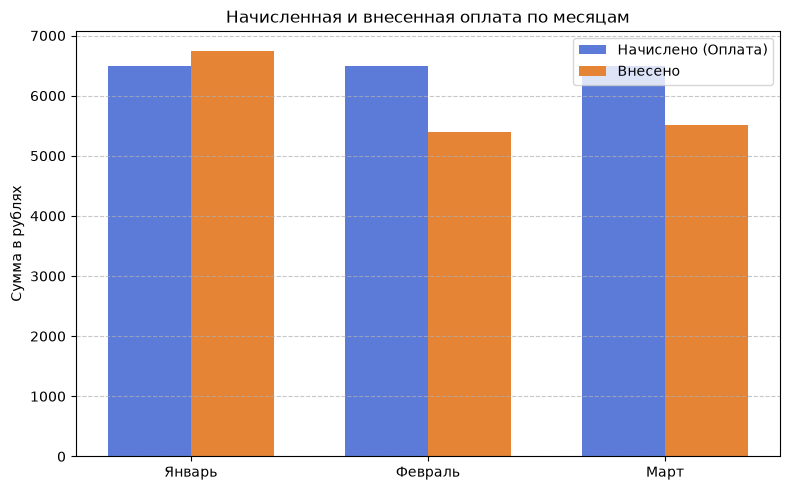

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Исходные данные
tariff = 2000  # Тариф без льгот
months = ["Январь", "Февраль", "Март"]
fio_list = ["Иванов И.И.", "Петров П.П.", "Сидоров С.С.", "Смирнов А.А."]
phone_list = ["+79001112233", "+79004445566", "+79007778899", "+79002223344"]
lgotas = [0, 1, 2, 0]  #Распределим льготы

#(12 записей, 4 фамилии повторяются в 3 месяцах)
data = []
idx = 1
np.random.seed(42)  # Для воспроизводимости случайных значений Внесено

for month in months:
    for i in range(len(fio_list)):
        vneseno = float(np.random.randint(500, 2001))
        data.append(
            {
                "№": idx,
                "Месяц": month,
                "ФИО": fio_list[i],
                "Номер телефона": phone_list[i],
                "Льгота": lgotas[i],
                "Внесено": vneseno,
            }
        )
        idx += 1

df = pd.DataFrame(data)

#расчета оплаты с учетом льготы
def calculate_oplata(lgota, base_tariff):
    if lgota == 0:
        return base_tariff
    elif lgota == 1:
        return base_tariff * 0.75
    elif lgota == 2:
        return base_tariff * 0.50
    return base_tariff


df["Оплата"] = df["Льгота"].apply(lambda x: calculate_oplata(x, tariff))
df["Долг"] = df["Оплата"] - df["Внесено"]

df = df[
    [
        "№",
        "Месяц",
        "ФИО",
        "Номер телефона",
        "Льгота",
        "Оплата",
        "Внесено",
        "Долг",
    ]
]

print("ОСНОВНАЯ ТАБЛИЦА")
print(df.to_string(index=False))
print(f"\nТариф без льгот (вне таблицы): {tariff}\n")

total_vneseno = df["Внесено"].sum()
total_dolg = df["Долг"].sum()
mean_dolg = df["Долг"].mean()
count_above_mean = df[df["Долг"] > mean_dolg].shape[0]
min_dolg = df["Долг"].min()
max_dolg = df["Долг"].max()

print("СТАТИСТИКА И РАСЧЕТЫ")
print(f"3. Общая сумма внесенной оплаты: {total_vneseno:.2f}")
print(f"   Общая сумма долга: {total_dolg:.2f}")
print(f"4. Среднее значение по полю 'Долг': {mean_dolg:.2f}")
print(f"5. Количество абонентов с долгом больше среднего: {count_above_mean}")
print(f"6. Минимальный долг: {min_dolg:.2f}, Максимальный долг: {max_dolg:.2f}\n")

#по каждой фамилии
table_fio = df.groupby("ФИО")["Долг"].sum().reset_index()
print("--- 7. ТАБЛИЦА ДОЛГОВ ПО ФИО ---")
print(table_fio.to_string(index=False))
print()

#по месяцам
table_month = df.groupby("Месяц")[["Оплата", "Внесено"]].sum().reset_index()
table_month["Месяц"] = pd.Categorical(table_month["Месяц"], categories=months, ordered=True)
table_month = table_month.sort_values("Месяц")

print("ТАБЛИЦА ПО МЕСЯЦАМ")
print(table_month.to_string(index=False))


x = np.arange(len(table_month["Месяц"]))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width / 2, table_month["Оплата"], width, label="Начислено (Оплата)", color="#5c7bd9")
rects2 = ax.bar(x + width / 2, table_month["Внесено"], width, label="Внесено", color="#e58435")

ax.set_ylabel("Сумма в рублях")
ax.set_title("Начисленная и внесенная оплата по месяцам")
ax.set_xticks(x)
ax.set_xticklabels(table_month["Месяц"])
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()
